# 07 – Kepstrální analýza (Real Cepstrum Liftering), Hilbertova obálka a detektor STA/LTA
Homomorfní dekonvoluce $\mathcal{F}^{-1}\{\log|\mathcal{F}\{x(t)\}|\}$ oddělující buzení od přenosové funkce uložení senzoru (`odkryto` vs. `zakryto`), doplněná o analytickou obálku $A(t) = \sqrt{x(t)^2 + \mathcal{H}\{x(t)\}^2}$ a náběhový poměr **STA/LTA**.

Metriky separability (Kepstrum + Hilbert + STA/LTA): {'method_name': 'cepstrum', 'fdr_score': 0.1797, 'silhouette_score': -0.0793, 'davies_bouldin_score': 10.9515, 'mutual_info_mean': 0.2277, 'anova_f_mean': 186.0158, 'separability_by_phenomenon': {'static_load_fdr': 0.0511, 'thermal_fdr': 0.1764, 'transition_edge_fdr': 0.0016}}


,measurement_code,inherited_label,cepstrum_low_quef_energy,hilbert_env_max,sta_lta_max_ratio
0,0773,klid_pred_teplotou,0.058000,0.000408,1.805578
1,0773,klid_pred_teplotou,0.058329,0.000426,1.996887
2,0773,klid_pred_teplotou,0.050791,0.000433,2.481758
3,0773,klid_pred_teplotou,0.203099,0.000553,2.081196
4,0773,klid_pred_teplotou,0.146952,0.001062,2.748398
5,0773,klid_pred_teplotou,0.118267,0.000702,2.131647
6,0773,klid_pred_teplotou,0.190106,0.000408,2.595829
7,0773,klid_pred_teplotou,0.099582,0.000512,2.393301
8,0773,klid_pred_teplotou,0.147560,0.000534,2.950963
9,0773,klid_pred_teplotou,0.188189,0.000548,2.399688


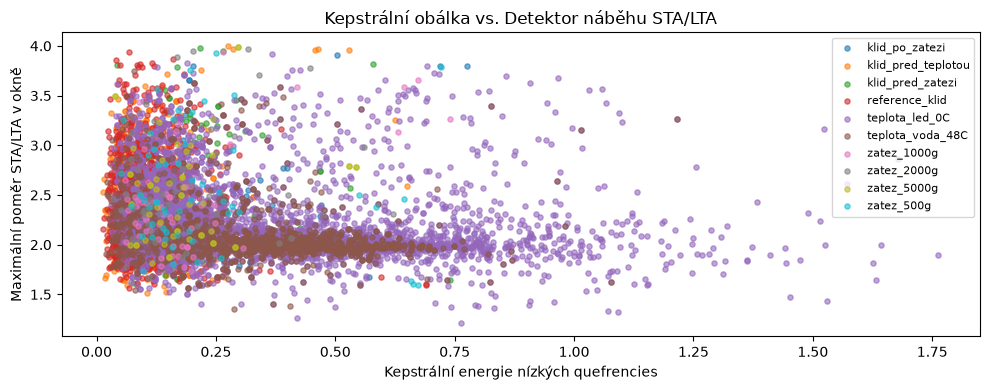

In [1]:
import matplotlib.pyplot as plt
from icaros.analysis.runner import load_windows_with_signals, run_single_silver_method
from icaros.db.s3 import read_parquet_from_s3

df_win, signals, fs = load_windows_with_signals("win128_stride32")
res = run_single_silver_method("cepstrum", df_win, signals, fs, "win128_stride32")
print("Metriky separability (Kepstrum + Hilbert + STA/LTA):", {k: v for k, v in res.items() if k != "s3_uri"})
df_cep = read_parquet_from_s3(res["s3_uri"])
display(df_cep[["measurement_code", "inherited_label", "cepstrum_low_quef_energy", "hilbert_env_max", "sta_lta_max_ratio"]].head(12))

fig, ax = plt.subplots(figsize=(10, 4))
for lbl, grp in df_cep.groupby("inherited_label"):
    ax.scatter(grp["cepstrum_low_quef_energy"], grp["sta_lta_max_ratio"], s=14, alpha=0.6, label=lbl)
ax.set_xlabel("Kepstrální energie nízkých quefrencies")
ax.set_ylabel("Maximální poměr STA/LTA v okně")
ax.set_title("Kepstrální obálka vs. Detektor náběhu STA/LTA")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()